# 02 — LogisticRegression da aula PL6 adaptada aos voos

O estimador é exatamente `LogisticRegression(max_iter=200, C=C)`, com C em `[0.1, 1.0, 10.0]`, como em LAIA_PL6. Os restantes parâmetros ficam nos valores por omissão do scikit-learn. O original da aula mantém-se na pasta LAIA_PL6, fora deste repositório.

Adaptaram-se Iris para voos, a preparação dos inputs e a avaliação cronológica. C é escolhido pela accuracy média na validação; macro-F1 e métricas por classe são complementares. Não se usa SGD, ponderação balanced ou rota no classificador.

As métricas seguintes são lidas da execução real. O período de teste já tinha sido reportado para o modelo anterior; não é um teste novo nunca observado. A mudança de estimador foi solicitada por correspondência com a aula, e a escolha de C continua restrita aos períodos anteriores.


In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd().resolve(), Path.cwd().resolve().parent]
             if (p / "configs/baseline.json").exists()), None)
if ROOT is None:
    raise RuntimeError("Abrir a partir da raiz do repositório ou de notebooks/.")
sys.path.insert(0, str(ROOT / "src"))
from flight_delay.data.audit import BASE_FEATURES
from flight_delay.features.build import FlightFeatures
from flight_delay.data.prepare import preparation_signature
from flight_delay.models.pipeline import CLASSES

DATA = ROOT / "data/processed"
REPORTS = ROOT / "reports/generated/baseline"
required = [DATA / "manifest.json", ROOT / "models/selection.json", REPORTS / "holdout.json"]
if not all(p.exists() for p in required):
    raise RuntimeError("Executar primeiro: python train.py")
config = json.loads((ROOT / "configs/baseline.json").read_text())
manifest = json.loads((DATA / "manifest.json").read_text())
selection = json.loads((ROOT / "models/selection.json").read_text())
holdout = json.loads((REPORTS / "holdout.json").read_text())
assert selection["model_sha256"] == holdout["model_sha256"]
assert selection["provenance"]["data_manifest_sha256"] == hashlib.sha256((DATA / "manifest.json").read_bytes()).hexdigest()
assert manifest["preparation_config_sha256"] == preparation_signature(config)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
print("Configuração, manifesto e avaliação da mesma seleção carregados.")


Configuração, manifesto e avaliação da mesma seleção carregados.


## 1. O que foi preparado

Só entram voos não cancelados, não desviados e com ArrDelay numérico finito. As classes são on_time (<15), moderate_delay ([15,60)) e severe_delay (>=60). Datas inválidas são colocadas em quarentena. Duração prevista ou distância inválida passa a ausência; a imputação é ajustada só no treino de cada fold.

A tabela preparada conserva o alvo, o atraso, número de voo, identificador de origem e split como metadados. A seleção de X no pipeline é explícita: esses campos não entram automaticamente por existirem na tabela. Os CSV originais são preservados.


In [2]:
display(pd.DataFrame(manifest["counts"].items(), columns=["Etapa/controlo", "Registos"]))
display(pd.DataFrame(manifest["sources"])[["file", "rows", "bytes", "sha256"]])
monthly = pd.DataFrame(manifest["monthly_counts"])
display(monthly.groupby("split")["rows"].sum().to_frame())
display(pd.DataFrame(manifest["invalid_duration_examples"]))


,Etapa/controlo,Registos
0,raw,13577024
1,eligible,13275415
2,quarantined_invalid_date,0
3,invalid_duration_to_missing,5
4,invalid_distance_to_missing,0
5,prepared,13275415


,file,rows,bytes,sha256
0,flights_2022.csv,6729125,3034870106,15d1c67edfed9f3d3562a20738d1bbc6a2b86eb18298d4...
1,flights_2023.csv,6847899,3095432607,5a74f1609f5a0725093a394728b2b3dbf018a9946ed3df...


,rows
split,
test,3463444
train,6532012
validation,3279959


,row_id,FlightDate,Origin,Dest,CRSElapsedTime
0,202200388368,2022-01-21,BNA,EWR,-48.00
1,202205219235,2022-10-14,IND,LGA,-44.00
2,202205219246,2022-10-23,PIT,BOS,-36.00
3,202206449166,2022-12-06,PIT,BOS,-85.00
4,202301465110,2023-03-23,JFK,PWM,-5.00


## 2. Divisão temporal e amostra

Mantêm-se os três folds cronológicos e o intervalo de sete dias antes de cada validação/teste. As pastas train/validation/test não substituem os cortes por data. O treino usa até 30 000 voos por mês por prioridades determinísticas independentes do alvo; validação e teste usam todos os voos dos períodos respetivos.

A amostra disponível inclui os 24 meses, mas só o subconjunto anterior ao corte de treino entra no fit. Nesta adaptação não existe refit posterior com o período de teste. Não se simula o calendário de publicação de labels BTS, porque não há timestamps dessa publicação.


In [3]:
sample = pd.read_parquet(DATA / "monthly_sample.parquet")
display(sample.groupby("month").size().rename("train_sample_rows").to_frame())
folds = []
for fold in config["folds"]:
    cutoff = (pd.Timestamp(fold["validation_start"]) - pd.Timedelta(days=config["gap_days"])).strftime("%Y-%m-%d")
    folds.append({"fold": fold["name"], "train_end_exclusive": cutoff,
                  "validation_start": fold["validation_start"], "validation_end_exclusive": fold["validation_end"],
                  "sample_train_rows": int(sample.FlightDate.lt(cutoff).sum())})
display(pd.DataFrame(folds))
assert sample.row_id.is_unique
print("Amostra disponível; o teste não é usado no treino:", len(sample))


,train_sample_rows
month,
2022-01,30000
2022-02,30000
2022-03,30000
2022-04,30000
2022-05,30000
2022-06,30000
2022-07,30000
2022-08,30000
2022-09,30000


,fold,train_end_exclusive,validation_start,validation_end_exclusive,sample_train_rows
0,2022_Q4,2022-09-24,2022-10-01,2023-01-01,263271
1,2023_Q1,2022-12-25,2023-01-01,2023-04-01,353859
2,2023_Q2,2023-03-25,2023-04-01,2023-07-01,443254


Amostra disponível; o teste não é usado no treino: 720000


## 3. Exploração apenas no treino do primeiro fold

As proporções seguintes usam só voos anteriores ao primeiro corte de treino, sem validação/teste. A relação entre companhia, horário e atraso é descritiva e pode refletir outras variáveis. Não demonstra causalidade ou importância independente.

Esta exploração não altera os três valores de C da aula. O treino e a escolha são executados em train.py e as métricas de validação identificam a variante usada.


Voos na exploração de treino: 4776645


target,on_time,moderate_delay,severe_delay,total
group,,,,
WN,682193,170549,60230,912972
DL,530466,70150,34829,635445
AA,466901,88212,50342,605455
OO,450402,55767,34083,540252
UA,348579,55061,31362,435002
YX,181897,29846,18066,229809
B6,126092,34207,27632,187931
MQ,152129,21312,9466,182907
9E,141424,16837,10682,168943


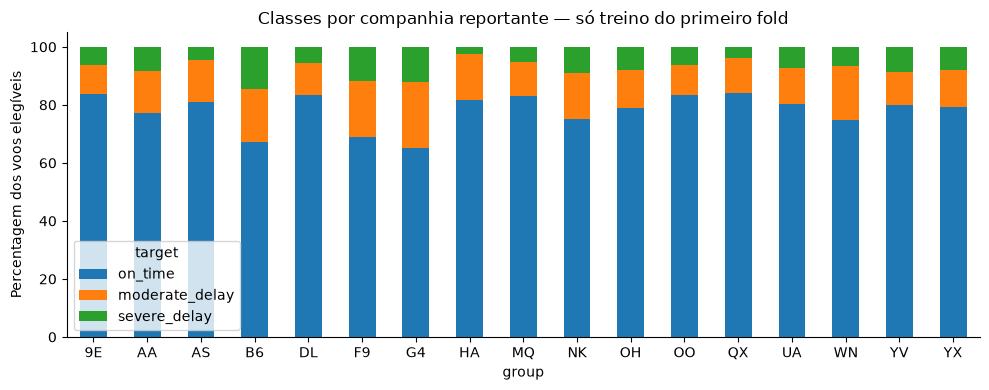

In [4]:
eda_path = REPORTS / "eda_training_groups.csv"
cutoff = folds[0]["train_end_exclusive"]
eda_is_current = eda_path.exists() and eda_path.stat().st_mtime_ns >= (DATA / "manifest.json").stat().st_mtime_ns
if not eda_is_current:
    counts = Counter()
    fields = ["Reporting_Airline", "Origin", "Dest", "month", "weekday", "departure_hour"]
    for path in sorted(DATA.glob("*/month=*/*.parquet")):
        month = path.parent.name.split("=", 1)[1]
        if month > cutoff[:7]:
            continue
        frame = pd.read_parquet(path)
        frame = frame.loc[frame.FlightDate.lt(cutoff)]
        if frame.empty:
            continue
        features = FlightFeatures().transform(frame[BASE_FEATURES])
        for field in fields:
            grouped = pd.DataFrame({"group": features[field].astype(str), "target": frame.target.astype(str)})
            for (group, target), count in grouped.value_counts().items():
                counts[(field, group, target)] += int(count)
    pd.DataFrame([{"field": field, "group": group, "target": target, "count": count}
                  for (field, group, target), count in sorted(counts.items())]).to_csv(eda_path, index=False)
eda = pd.read_csv(eda_path, dtype={"group": str})
carriers = eda.loc[eda.field.eq("Reporting_Airline")].pivot(index="group", columns="target", values="count").reindex(columns=CLASSES).fillna(0)
carrier_counts = carriers.sum(axis=1)
print("Voos na exploração de treino:", int(carrier_counts.sum()))
display(carriers.assign(total=carrier_counts).sort_values("total", ascending=False))
carrier_rates = carriers.div(carrier_counts, axis=0) * 100
carrier_rates.plot.bar(stacked=True, ylabel="Percentagem dos voos elegíveis", title="Classes por companhia reportante — só treino do primeiro fold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 4. Horário previsto e classes

Relacionamos a hora prevista de partida com a proporção das classes no treino. Estas proporções não são usadas como features de target encoding. O modelo recebe a hora prevista, não uma taxa calculada com resultados futuros.

O valor 2400 é convertido em hora 0. A hora é local ao aeroporto; as diferenças entre horas podem refletir também diferenças entre aeroportos e rotas.


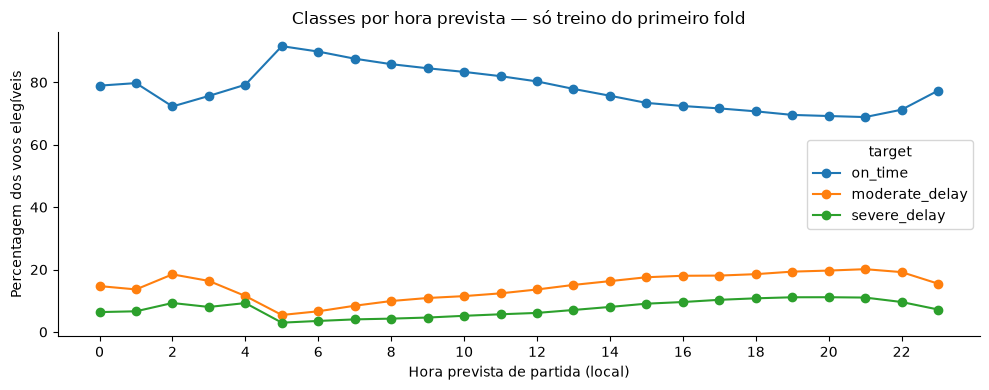

In [5]:
hours = eda.loc[eda.field.eq("departure_hour")].pivot(index="group", columns="target", values="count").reindex(columns=CLASSES).fillna(0)
hours.index = hours.index.astype(int)
hours = hours.sort_index()
hour_rates = hours.div(hours.sum(axis=1), axis=0) * 100
hour_rates.plot(marker="o", ylabel="Percentagem dos voos elegíveis", xlabel="Hora prevista de partida (local)", title="Classes por hora prevista — só treino do primeiro fold")
plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()


## 5. Comparar os três valores de C da aula

O construtor usado é `LogisticRegression(max_iter=200, C=C)`, sem class_weight ou outros argumentos adicionais. O pipeline anterior transforma dados categóricos e numéricos dos voos; a classe do estimador e os argumentos explícitos correspondem ao exemplo fornecido.

Comparam-se C=0.1, 1.0 e 10.0 nos três folds. A referência maioritária é apenas uma comparação: não é candidata à escolha de C. Escolhe-se a maior accuracy média de validação, mantendo a métrica da aula e evitando escolher C no teste. As barras mostram desvio padrão entre três folds, não intervalos de confiança.

O limite de 200 iterações é mantido mesmo que existam avisos de convergência; esses avisos são apresentados na tabela.


,fold,model,C,train_rows,validation_rows,macro_f1,accuracy,severe_recall,fit_seconds,iterations,convergence_warnings
0,2022_Q4,majority,NaN,263271,1630906,0.295213,0.794751,0.000000,1.685,0,[]
1,2022_Q4,logistic_C0.1,0.1,263271,1630906,0.295702,0.794602,0.000207,6.434,114,[]
2,2022_Q4,logistic_C1.0,1.0,263271,1630906,0.296696,0.794364,0.000800,7.068,144,[]
3,2022_Q4,logistic_C10.0,10.0,263271,1630906,0.297025,0.794335,0.001007,8.295,173,[]
4,2023_Q1,majority,NaN,353859,1591477,0.292716,0.782764,0.000000,2.219,0,[]
5,2023_Q1,logistic_C0.1,0.1,353859,1591477,0.292887,0.782725,0.000000,7.787,92,[]
6,2023_Q1,logistic_C1.0,1.0,353859,1591477,0.293078,0.782681,0.000080,11.026,159,[]
7,2023_Q1,logistic_C10.0,10.0,353859,1591477,0.293253,0.782664,0.000134,12.762,159,[]
8,2023_Q2,majority,NaN,443254,1688482,0.290784,0.773602,0.000000,2.485,0,[]
9,2023_Q2,logistic_C0.1,0.1,443254,1688482,0.290909,0.773556,0.000000,9.997,112,[]


,mean,std
model,,
majority,0.783706,0.010606
logistic_C0.1,0.783628,0.010552
logistic_C1.0,0.783527,0.010440
logistic_C10.0,0.783494,0.010450


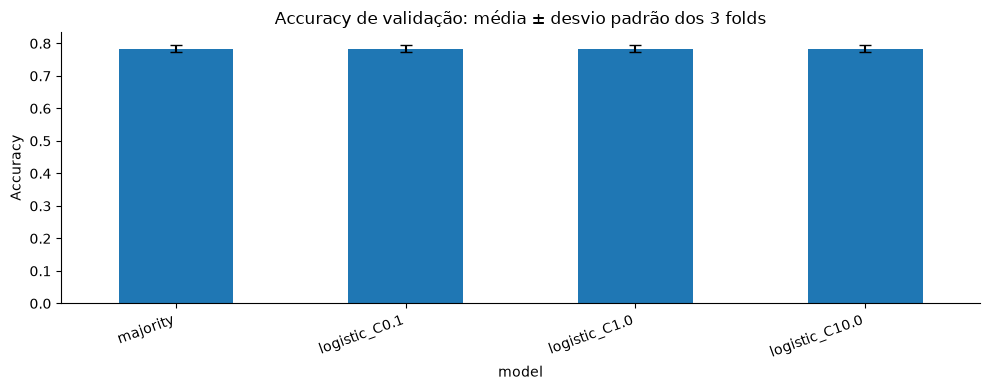

C escolhido pela accuracy de validação: 0.1
Treino final de desenvolvimento: {'train_rows': 533267, 'fit_seconds': 12.334, 'convergence_warnings': [], 'iterations': 115}


In [6]:
cv = pd.read_csv(REPORTS / "cross_validation.csv")
display(cv[["fold", "model", "C", "train_rows", "validation_rows", "macro_f1", "accuracy", "severe_recall", "fit_seconds", "iterations", "convergence_warnings"]])
comparison = cv.groupby("model")["accuracy"].agg(["mean", "std"]).sort_values("mean", ascending=False)
display(comparison)
comparison["mean"].plot.bar(yerr=comparison["std"], capsize=4, ylabel="Accuracy", title="Accuracy de validação: média ± desvio padrão dos 3 folds")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()
print("C escolhido pela accuracy de validação:", selection["variant"]["C"])
print("Treino final de desenvolvimento:", selection["fit"])


## 6. Avaliar o modelo escolhido no período de teste

O teste inclui todos os voos preparados de julho a dezembro de 2023. Não participa na escolha de C. Este período já foi observado na implementação anterior; a nova avaliação não é apresentada como um novo holdout independente nunca visto.

Accuracy pode favorecer previsões da classe maioritária. Macro-F1, precision e recall por classe são indispensáveis para identificar esse efeito. Não foi definido um critério operacional de aceitação pela equipa.


,model,rows,macro_f1,accuracy,severe_recall
0,baseline,3463444,0.298480,0.809781,0.000037
1,majority,3463444,0.298304,0.809812,0.000000


,precision,recall,f1,support
on_time,0.809839,0.999922,0.894898,2804740.0
moderate_delay,0.292614,0.000234,0.000467,440377.0
severe_delay,0.228571,0.000037,0.000073,218327.0


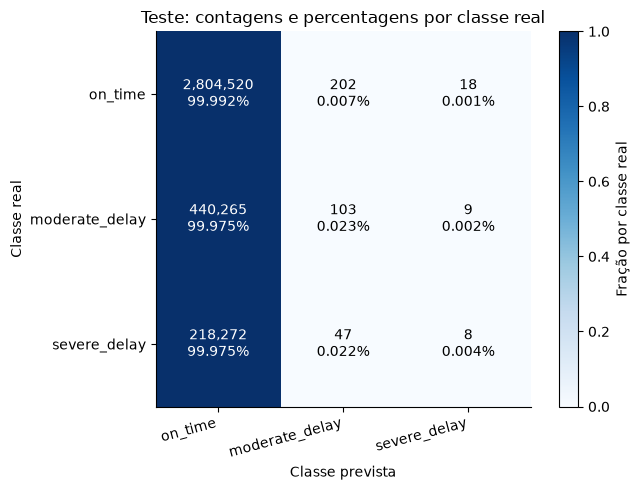

In [7]:
results = holdout["models"]
display(pd.DataFrame([{ "model": name, "rows": result["rows"], "macro_f1": result["macro_f1"],
                       "accuracy": result["accuracy"], "severe_recall": result["classes"]["severe_delay"]["recall"]}
                     for name, result in results.items()]))
baseline = results["baseline"]
display(pd.DataFrame(baseline["classes"]).T)
matrix = np.asarray(baseline["confusion_matrix"])
normalized = np.divide(matrix, matrix.sum(axis=1, keepdims=True), out=np.zeros_like(matrix, dtype=float), where=matrix.sum(axis=1, keepdims=True) != 0)
fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(normalized, vmin=0, vmax=1, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{matrix[i,j]:,}\n{normalized[i,j]:.3%}", ha="center", va="center", color="white" if normalized[i,j] > .5 else "black")
ax.set(xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES,
       xlabel="Classe prevista", ylabel="Classe real", title="Teste: contagens e percentagens por classe real")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
fig.colorbar(image, ax=ax, label="Fração por classe real")
fig.tight_layout()
plt.show()


## 7. Resultados por período e subgrupo

O agregado pode esconder diferenças por mês, companhia ou origem. As tabelas incluem o número de exemplos e o suporte da classe severa. O macro-F1 é calculado sempre nas três classes; em grupos sem exemplos de uma classe, o respetivo F1 é zero. Não comparar grupos pequenos como se as estimativas fossem igualmente estáveis.

Estas métricas do teste são apresentadas para avaliar o modelo já fixado. Não foram usadas para refazer a seleção desta execução. O futuro sistema de monitorização terá de ligar previsões a labels atrasadas e definir alertas; este relatório não implementa esse serviço.


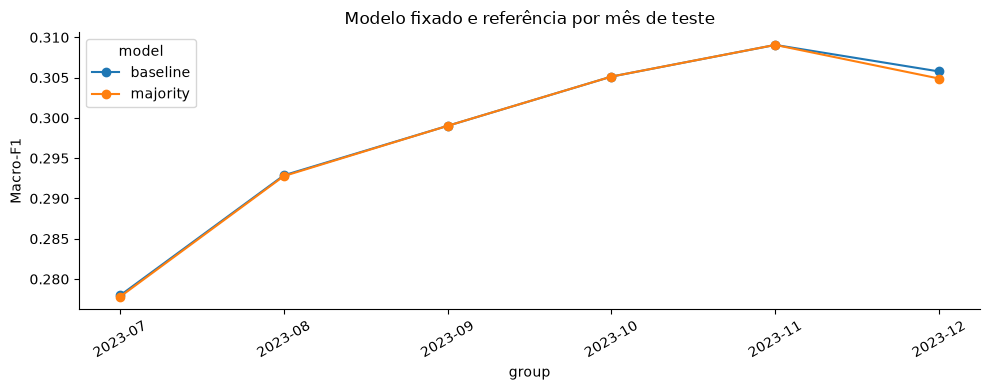

Subgrupo: Reporting_Airline — 15 maiores por número de voos


,model,field,group,rows,macro_f1,accuracy,severe_recall,severe_support
357,baseline,Reporting_Airline,WN,742276,0.294583,0.791444,0.000000,36329
348,baseline,Reporting_Airline,DL,502828,0.307880,0.858116,0.000000,24732
345,baseline,Reporting_Airline,AA,473485,0.293453,0.786289,0.000000,38305
356,baseline,Reporting_Airline,UA,372947,0.300699,0.821653,0.000000,23625
355,baseline,Reporting_Airline,OO,344411,0.305973,0.848292,0.000000,19109
358,baseline,Reporting_Airline,YX,136620,0.311762,0.878437,0.000000,5747
353,baseline,Reporting_Airline,NK,130879,0.281791,0.732027,0.000000,12877
347,baseline,Reporting_Airline,B6,128203,0.268964,0.673370,0.000412,19439
346,baseline,Reporting_Airline,AS,125242,0.299901,0.817689,0.000000,5026
352,baseline,Reporting_Airline,MQ,118237,0.303267,0.834527,0.000000,5259


Subgrupo: Origin — 15 maiores por número de voos


,model,field,group,rows,macro_f1,accuracy,severe_recall,severe_support
20,baseline,Origin,ATL,170881,0.301787,0.827084,0.000000,9121
90,baseline,Origin,DEN,149554,0.289859,0.767342,0.000000,10542
91,baseline,Origin,DFW,149035,0.293736,0.787640,0.000000,10812
235,baseline,Origin,ORD,130774,0.293983,0.788827,0.000000,9274
69,baseline,Origin,CLT,99619,0.291254,0.775826,0.000000,8084
181,baseline,Origin,LAX,99075,0.301792,0.827111,0.000000,5138
179,baseline,Origin,LAS,96370,0.289911,0.765072,0.000000,6303
247,baseline,Origin,PHX,89324,0.301929,0.827795,0.000000,4357
291,baseline,Origin,SEA,86325,0.299664,0.816519,0.000000,3464
201,baseline,Origin,MCO,81631,0.282440,0.730041,0.000451,8864


In [8]:
subgroups = pd.read_csv(REPORTS / "holdout_subgroups.csv", dtype={"group": str})
monthly_scores = subgroups.loc[subgroups.field.eq("month")].pivot(index="group", columns="model", values="macro_f1")
monthly_scores.plot(marker="o", ylabel="Macro-F1", title="Modelo fixado e referência por mês de teste")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
for field in ["Reporting_Airline", "Origin"]:
    selected = subgroups.loc[subgroups.field.eq(field) & subgroups.model.eq("baseline")]
    print("Subgrupo:", field, "— 15 maiores por número de voos")
    display(selected.sort_values("rows", ascending=False).head(15))


## 8. Pipeline guardado para entregar aos colegas

models/model.joblib contém a preparação e o classificador avaliados. Não há treino posterior no teste. O nome base acordado é model.

O exemplo sintético seguinte verifica a previsão local com dois voos. A API e o registo no MLflow são responsabilidade dos colegas.

In [9]:
import joblib
from sklearn.linear_model import LogisticRegression
from flight_delay.models.inference import classify_payload
model = joblib.load(ROOT / "models/model.joblib")
metadata = json.loads((ROOT / "models/model_metadata.json").read_text())
assert metadata["sha256"] == hashlib.sha256((ROOT / "models/model.joblib").read_bytes()).hexdigest()
assert metadata["sha256"] == selection["model_sha256"]
assert isinstance(model[-1], LogisticRegression)
assert model[-1].get_params() == LogisticRegression(max_iter=200, C=metadata["C"]).get_params()
request = json.loads((ROOT / "examples/classify_request.json").read_text())
display(request)
display(classify_payload(model, request))
display(pd.DataFrame(metadata["provenance"]["versions"].items(), columns=["dependency", "version"]))


{'instances': [{'FlightDate': '2025-05-15',
   'Reporting_Airline': 'AA',
   'Origin': 'JFK',
   'Dest': 'LAX',
   'CRSDepTime': '0900',
   'CRSArrTime': '1215',
   'CRSElapsedTime': 375,
   'Distance': 2475},
  {'FL_DATE': '2025-05-16',
   'Reporting_Airline': 'NEW_CARRIER',
   'Origin': 'NEW_AIRPORT',
   'Dest': 'LAX',
   'CRSDepTime': '2400',
   'CRSArrTime': '0600',
   'CRSElapsedTime': 180,
   'Distance': 1000}]}

{'classifications': ['on_time', 'on_time']}

,dependency,version
0,numpy,2.4.6
1,pandas,3.0.3
2,scikit-learn,1.9.0
3,scipy,1.18.0
4,pyarrow,23.0.1
5,joblib,1.5.3


## 9. Executar a parte 1

- `python train.py`: preparar, comparar os três C na validação, guardar e avaliar. Reutiliza resultados verificados quando existem; `--retrain` repete o ajuste.
- `python scripts/predict.py --input examples/classify_request.json`: previsão local.
- `python -m unittest discover -s tests -v`: testes de dados, features, separação temporal e treino.
- `Dockerfile.train`: preparação, treino e avaliação num container. Comandos e mounts em docs/model-handoff.md.

O estimador e o grid de C correspondem à aula; dados, preparação e avaliação cronológica estão adaptados aos voos. Esta entrega não implementa API, servidor MLflow ou workflows. DVC continua adiado.